# MSDS 565 — Project 3: Movie Genre Classification
## Notebook 2 — Vectorization, Modeling & LLM Distillation

**Team:** teamtim (solo project)

I'm keeping the setup consistent with Notebook 1: a 100-vote minimum, the original MPST splits, and **Action, Comedy, and Horror** as the three targets. The plot synopsis is the **only feature**. I use IMDB genre labels as targets and other metadata only for filtering, splitting, and reporting. This notebook runs in order and saves the models and preprocessing objects that Notebook 3 needs.

**Run note:** The sentence embedding step is CPU-intensive the first time. The LLM annotation step requires a valid API key and makes up to 300 paid API calls. Nothing is labeled or reported as completed until the actual calls run.

### 0. Setup and dependencies

I'm using `sentence-transformers/all-MiniLM-L6-v2` (384-dimensional embeddings) alongside TF-IDF. That gives me a straightforward word-level representation and a second representation focused more on meaning. Both use logistic regression, so I can compare features without changing the classifier.

My LLM teacher is `gpt-4o-mini`. I'm using the OpenAI API to label **only** the sampled training synopses, not the test set. These are real paid API calls, not generated example labels.

**Environment:** I've already configured the `moviegenre` conda environment on my Mac. I'm not running package-install cells inside the notebook because that previously caused NumPy/PyTorch conflicts. I keep the dataset in the local project folder and don't commit it or the annotation/cache CSV files to GitHub.

In [1]:
from pathlib import Path
import os, json, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.base import clone
from IPython.display import display

RANDOM_STATE = 42
TEAM_NAME = "teamtim"  # change before submission
GENRES = ["Action", "Comedy", "Horror"]
MIN_VOTES = 100
EMBEDDING_ID = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_SHORT = "emb-minilm"
TEACHER_MODEL = "gpt-4o-mini"

# Detect the project root even if Jupyter starts in the notebooks/ directory.
ROOT = Path.cwd()
for candidate in [ROOT, ROOT.parent, ROOT.parent.parent]:
    if (candidate / "mpst_imdb_movies.csv").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Place mpst_imdb_movies.csv next to this notebook or in its parent folder.")
MODEL_DIR = ROOT / "models"
ARTIFACT_DIR = ROOT / "local_artifacts"  # ignored by git
MODEL_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("Model directory:", MODEL_DIR)

Project root: /Users/timhamilton/Downloads
Model directory: /Users/timhamilton/Downloads/models


### 1. Load, filter, and split

I'm merging the original training and validation splits as instructed, while keeping the original test split untouched. That gives me one consistent held-out test set for **every** model. The 100-vote rule carries over from EDA so I'm comparing the same movie population.

In [2]:
df = pd.read_csv(ROOT / "mpst_imdb_movies.csv", low_memory=False)
required = {"imdb_id", "primaryTitle", "plot_synopsis", "numVotes", "split", *GENRES}
assert required.issubset(df.columns), f"Missing columns: {required - set(df.columns)}"
df["numVotes"] = pd.to_numeric(df["numVotes"], errors="coerce")
df = df[df["numVotes"] >= MIN_VOTES].copy()
df["split"] = df["split"].astype(str).str.lower().str.strip()
df["plot_synopsis"] = df["plot_synopsis"].fillna("").astype(str)
df = df[df["plot_synopsis"].str.strip().ne("")].copy()
for genre in GENRES:
    df[genre] = pd.to_numeric(df[genre], errors="raise").astype(int)
train_df = df[df["split"].isin(["train", "val"])].copy().reset_index(drop=True)
test_df = df[df["split"].eq("test")].copy().reset_index(drop=True)
assert len(train_df) > 0 and len(test_df) > 0
assert not set(train_df.imdb_id).intersection(set(test_df.imdb_id)), "Train/test leakage"
rate_table = pd.DataFrame({"train_positives_pct": (100 * train_df[GENRES].mean()).round(2),
                           "test_positives_pct": (100 * test_df[GENRES].mean()).round(2)})
print(f"Train + val: {len(train_df):,} | Test: {len(test_df):,} | Filter: {MIN_VOTES}+ votes")
display(rate_table)
assert (rate_table >= 5).all().all(), "One of the three genres does not meet the 5% minimum"

Train + val: 9,365 | Test: 2,330 | Filter: 100+ votes


,train_positives_pct,test_positives_pct
Action,22.19,23.18
Comedy,30.46,29.18
Horror,17.50,18.88


**Why I chose these genres:** I picked Action, Comedy, and Horror because they're genres I'm familiar with, but they also give me three distinct classification problems. Each exceeds the 5% positive-label threshold in both splits. A movie can belong to multiple genres, so I'm fitting three separate binary classifiers rather than forcing one label per movie.

### 2. Build two text representations

TF-IDF is the direct vocabulary baseline: it should be strong when genre-specific words really matter. Sentence embeddings test whether broader plot meaning helps beyond individual terms. The vectorizer and scalers are **fit on training text only**. I cache the embeddings locally so I don't have to recompute them every time I reopen Jupyter.

In [3]:
X_train_text = train_df["plot_synopsis"].tolist()
X_test_text = test_df["plot_synopsis"].tolist()

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.95,
                             max_features=20000, stop_words="english", dtype=np.float32)
X_train_tfidf_raw = vectorizer.fit_transform(X_train_text)
X_test_tfidf_raw = vectorizer.transform(X_test_text)
tfidf_scaler = StandardScaler(with_mean=False)
X_train_tfidf = tfidf_scaler.fit_transform(X_train_tfidf_raw)
X_test_tfidf = tfidf_scaler.transform(X_test_tfidf_raw)
joblib.dump(vectorizer, MODEL_DIR / "P3_N2_tfidf_vectorizer.pkl")
joblib.dump(tfidf_scaler, MODEL_DIR / "P3_N2_tfidf_scaler.pkl")
print("TF-IDF shapes:", X_train_tfidf.shape, X_test_tfidf.shape)

TF-IDF shapes: (9365, 20000) (2330, 20000)


In [4]:
# First run downloads the open-source sentence embedding model and encodes the text.
# Later runs reuse the cached arrays. Cache is OUTSIDE the repo.
from sentence_transformers import SentenceTransformer
embedder = SentenceTransformer(EMBEDDING_ID)
train_cache = ARTIFACT_DIR / "minilm_train_embeddings.npy"
test_cache = ARTIFACT_DIR / "minilm_test_embeddings.npy"
if train_cache.exists() and test_cache.exists():
    X_train_emb_raw = np.load(train_cache)
    X_test_emb_raw = np.load(test_cache)
    assert X_train_emb_raw.shape[0] == len(train_df) and X_test_emb_raw.shape[0] == len(test_df), "Cache doesn't match data"
else:
    X_train_emb_raw = embedder.encode(X_train_text, batch_size=16, show_progress_bar=True,
                                     convert_to_numpy=True, normalize_embeddings=True)
    X_test_emb_raw = embedder.encode(X_test_text, batch_size=16, show_progress_bar=True,
                                    convert_to_numpy=True, normalize_embeddings=True)
    np.save(train_cache, X_train_emb_raw)
    np.save(test_cache, X_test_emb_raw)
assert X_train_emb_raw.shape[1] == 384, "Unexpected embedding dimensionality"
emb_scaler = StandardScaler()
X_train_emb = emb_scaler.fit_transform(X_train_emb_raw)
X_test_emb = emb_scaler.transform(X_test_emb_raw)
joblib.dump(emb_scaler, MODEL_DIR / "P3_N2_emb-minilm_scaler.pkl")
print("Sentence embedding shapes:", X_train_emb.shape, X_test_emb.shape)

/Applications/anaconda3/envs/moviegenre/lib/python3.12/site-packages/sentence_transformers/cross_encoder/CrossEncoder.py:13: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm, trange
/Applications/anaconda3/envs/moviegenre/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Batches: 100%|███████████████████████████████| 146/146 [01:27<00:00,  1.66it/s]

Sentence embedding shapes: (9365, 384) (2330, 384)


### 3. Tune class weights and evaluate the IMDB-trained models

I kept logistic regression fixed because I want to compare TF-IDF against sentence embeddings, not test a bunch of unrelated algorithms. I used stratified five-fold cross-validation and macro-F1 to give both the positive and negative classes weight in evaluation. Imbalance is handled through class weights only—no synthetic observations or resampling. I report the mean and standard deviation for each setting, then score the selected model on the held-out test data.

Training: tfidf Action


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Best weights: balanced; test macro-F1: 0.778
              precision    recall  f1-score   support

           0       0.89      0.91      0.90      1790
           1       0.68      0.63      0.65       540

    accuracy                           0.85      2330
   macro avg       0.79      0.77      0.78      2330
weighted avg       0.84      0.85      0.84      2330



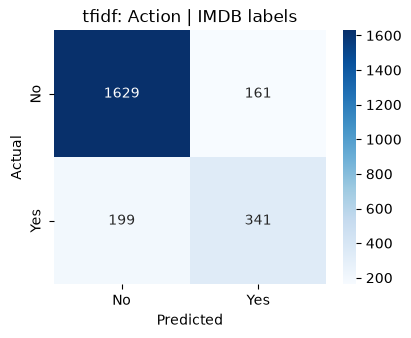

Training: tfidf Comedy
Best weights: balanced; test macro-F1: 0.733
              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1650
           1       0.64      0.60      0.62       680

    accuracy                           0.78      2330
   macro avg       0.74      0.73      0.73      2330
weighted avg       0.78      0.78      0.78      2330



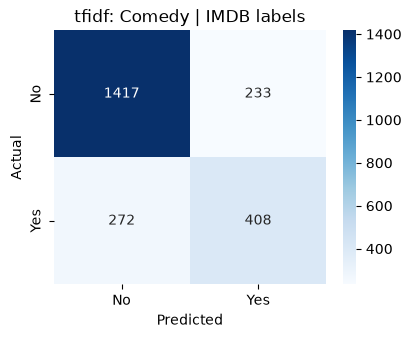

Training: tfidf Horror
Best weights: {0: 1, 1: 8}; test macro-F1: 0.830
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      1890
           1       0.77      0.68      0.72       440

    accuracy                           0.90      2330
   macro avg       0.85      0.82      0.83      2330
weighted avg       0.90      0.90      0.90      2330



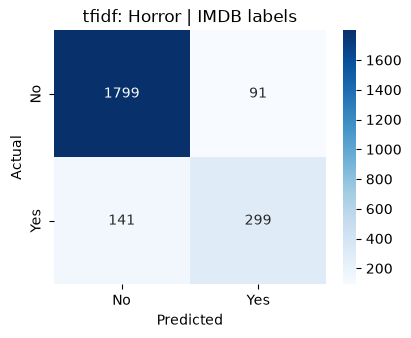

Training: emb-minilm Action
Best weights: {0: 1, 1: 2}; test macro-F1: 0.770
              precision    recall  f1-score   support

           0       0.90      0.88      0.89      1790
           1       0.63      0.68      0.65       540

    accuracy                           0.83      2330
   macro avg       0.76      0.78      0.77      2330
weighted avg       0.84      0.83      0.83      2330



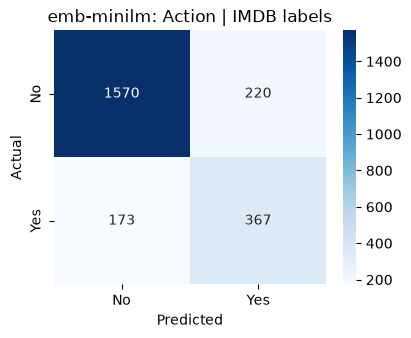

Training: emb-minilm Comedy
Best weights: None; test macro-F1: 0.693
              precision    recall  f1-score   support

           0       0.80      0.90      0.85      1650
           1       0.65      0.46      0.54       680

    accuracy                           0.77      2330
   macro avg       0.72      0.68      0.69      2330
weighted avg       0.76      0.77      0.76      2330



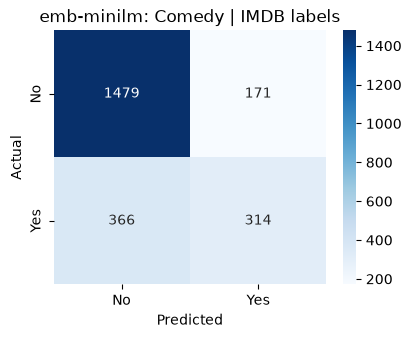

Training: emb-minilm Horror
Best weights: {0: 1, 1: 2}; test macro-F1: 0.757
              precision    recall  f1-score   support

           0       0.91      0.91      0.91      1890
           1       0.60      0.61      0.61       440

    accuracy                           0.85      2330
   macro avg       0.75      0.76      0.76      2330
weighted avg       0.85      0.85      0.85      2330



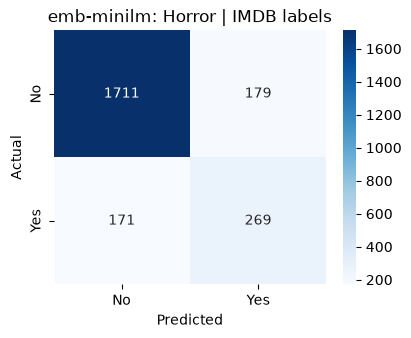

,representation,genre,class_weight,macro_f1_mean,macro_f1_std
0,tfidf,Action,None,0.763,0.006
1,tfidf,Action,balanced,0.773,0.008
2,tfidf,Action,"{0: 1, 1: 2}",0.767,0.009
3,tfidf,Action,"{0: 1, 1: 4}",0.772,0.008
4,tfidf,Action,"{0: 1, 1: 8}",0.773,0.010
5,tfidf,Comedy,None,0.745,0.010
6,tfidf,Comedy,balanced,0.749,0.009
7,tfidf,Comedy,"{0: 1, 1: 2}",0.748,0.009
8,tfidf,Comedy,"{0: 1, 1: 4}",0.748,0.010
9,tfidf,Comedy,"{0: 1, 1: 8}",0.748,0.010


In [5]:
WEIGHT_GRID = [None, "balanced", {0: 1, 1: 2}, {0: 1, 1: 4}, {0: 1, 1: 8}]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
representations = {"tfidf": (X_train_tfidf, X_test_tfidf),
                   EMBEDDING_SHORT: (X_train_emb, X_test_emb)}

def tune_logreg(X, y):
    model = LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE)
    search = GridSearchCV(model, {"class_weight": WEIGHT_GRID}, cv=cv, scoring="f1_macro",
                          n_jobs=2, refit=True, return_train_score=False)
    search.fit(X, y)
    return search

imdb_models = {}
cv_results = []
test_results = []
for rep, (X_train, X_test) in representations.items():
    for genre in GENRES:
        y_train = train_df[genre].to_numpy()
        y_test = test_df[genre].to_numpy()
        print("Training:", rep, genre)
        search = tune_logreg(X_train, y_train)
        imdb_models[(rep, genre)] = search.best_estimator_
        for setting, mean, std in zip(search.cv_results_["param_class_weight"],
                                      search.cv_results_["mean_test_score"],
                                      search.cv_results_["std_test_score"]):
            cv_results.append({"representation": rep, "genre": genre, "class_weight": str(setting),
                               "macro_f1_mean": mean, "macro_f1_std": std})
        predictions = search.predict(X_test)
        test_results.append({"label_source": "IMDB", "representation": rep, "genre": genre,
                             "macro_f1": f1_score(y_test, predictions, average="macro")})
        print(f"Best weights: {search.best_params_['class_weight']}; test macro-F1: {test_results[-1]['macro_f1']:.3f}")
        print(classification_report(y_test, predictions, zero_division=0))
        cm = confusion_matrix(y_test, predictions, labels=[0, 1])
        plt.figure(figsize=(4.4, 3.3))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
        plt.xlabel("Predicted"); plt.ylabel("Actual");plt.title(f"{rep}: {genre} | IMDB labels")
        plt.show()
        joblib.dump(search.best_estimator_, MODEL_DIR / f"P3_N2_{rep}_logreg_{genre.lower()}.pkl")
cv_table = pd.DataFrame(cv_results)
display(cv_table.assign(macro_f1_mean=cv_table.macro_f1_mean.round(3),
                        macro_f1_std=cv_table.macro_f1_std.round(3)))

### 4. Teacher annotation sample

Here's the actual distillation experiment: draw **100 known positives per selected genre from training only**, combine the draws, and remove duplicate IMDB IDs. The teacher sees only the synopsis and my three genre names, not the title, metadata, or true labels. This gives the LLM a realistic annotation task without turning this into a massive labeling job.

In [6]:
selected_rows = pd.concat([
    train_df.loc[train_df[genre].eq(1)].sample(n=100, random_state=RANDOM_STATE)
    for genre in GENRES
], ignore_index=True).drop_duplicates(subset="imdb_id").reset_index(drop=True)
assert len(selected_rows) <= 300
assert set(selected_rows.imdb_id).issubset(set(train_df.imdb_id))
print(f"Teacher sample: {len(selected_rows)} unique plots (maximum 300)")
display(selected_rows[GENRES].mean().rename("True positive rate in selected sample"))

Teacher sample: 299 unique plots (maximum 300)


Action    0.421405
Comedy    0.418060
Horror    0.371237
Name: True positive rate in selected sample, dtype: float64

In [14]:
import os
from getpass import getpass
from openai import OpenAI

new_key = getpass("Paste your NEW secret API key: ").strip()

if not new_key.startswith("sk-") or "..." in new_key:
    raise ValueError("Paste the complete secret key, not the masked version.")

os.environ["OPENAI_API_KEY"] = new_key
client = OpenAI(api_key=new_key)

print("Client configured with a key ending in:", new_key[-4:])

try:
    client.models.list()
    print("SUCCESS: API authentication works!")
except Exception as e:
    print(type(e).__name__ + ":", str(e)[:200])

del new_key

Paste your NEW secret API key:  ········


Client configured with a key ending in: 4EsA
SUCCESS: API authentication works!


In [15]:
from openai import OpenAI
# Set an environment variable before launching Jupyter or uncomment this once locally:
# os.environ["OPENAI_API_KEY"] = "your-key"   # never commit API keys
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError("OPENAI_API_KEY is not set. Configure it before running the teacher annotation cells.")
client = OpenAI()
schema = {
    "type": "json_schema",
    "json_schema": {
        "name": "movie_genre_labels", "strict": True,
        "schema": {"type": "object", "properties": {g: {"type": "boolean"} for g in GENRES},
                   "required": GENRES, "additionalProperties": False}
    }
}
TEACHER_PROMPT = ("Read the movie plot synopsis and judge whether it belongs to each of the "
                  "following movie genres: Action, Comedy, Horror. Base your decisions only "
                  "on the provided synopsis, not on guesses about the movie title. "
                  "A plot may belong to multiple genres. Return only the required JSON booleans.")

def annotate_synopsis(synopsis):
    response = client.chat.completions.create(
        model=TEACHER_MODEL, temperature=0, response_format=schema,
        messages=[{"role": "system", "content": TEACHER_PROMPT},
                  {"role": "user", "content": synopsis[:12000]}]
    )
    labels = json.loads(response.choices[0].message.content)
    assert set(labels) == set(GENRES) and all(type(labels[g]) is bool for g in GENRES)
    return labels, response.model

# Resume-safe checkpoint. Only rows with all three completed annotations are reused.
checkpoint = ARTIFACT_DIR / "teacher_checkpoint.csv"
previous = pd.read_csv(checkpoint) if checkpoint.exists() else pd.DataFrame()
by_id = {}
if not previous.empty:
    for _, r in previous.iterrows():
        if all(pd.notna(r.get(f"pred_{g.lower()}")) for g in GENRES):
            by_id[str(r["imdb_id"])] = r.to_dict()
recorded_models = set()
for i, row in selected_rows.iterrows():
    movie_id = str(row["imdb_id"])
    if movie_id in by_id:
        continue
    # Retry short-lived API failures; never silently generate substitute labels.
    for attempt in range(3):
        try:
            labels, served_model = annotate_synopsis(row["plot_synopsis"])
            recorded_models.add(served_model)
            break
        except Exception as exc:
            # A daily quota is not a temporary error; keep saved work and stop cleanly.
            if attempt == 2 or "requests per day" in str(exc).lower() or "no credits" in str(exc).lower():
                print(f"Stopped safely: {len(by_id)} annotations saved in {checkpoint}")
                raise
            time.sleep(2 ** (attempt + 1))
    result = {"imdb_id": movie_id, "primaryTitle": row["primaryTitle"],
              "plot_synopsis": row["plot_synopsis"]}
    result.update({f"pred_{g.lower()}": int(labels[g]) for g in GENRES})
    by_id[movie_id] = result
    pd.DataFrame(by_id.values()).to_csv(checkpoint, index=False)
    if (i + 1) % 25 == 0: print("Processed:", i + 1, "/", len(selected_rows))

pseudo = selected_rows[["imdb_id", "primaryTitle", "plot_synopsis"]].merge(
    pd.DataFrame(by_id.values()), on="imdb_id", suffixes=("", "_saved"), validate="one_to_one")
pseudo = pseudo[["imdb_id", "primaryTitle", "plot_synopsis"] + [f"pred_{g.lower()}" for g in GENRES]]
assert len(pseudo) == len(selected_rows) and pseudo.notna().all().all()
pseudo.to_csv(ARTIFACT_DIR / "pseudo_labeled.csv", index=False)
(ARTIFACT_DIR / "teacher_info.json").write_text(json.dumps({"requested_model": TEACHER_MODEL,
    "served_models_this_run": sorted(recorded_models), "truncation_characters": 12000,
    "annotated_movies": len(pseudo)}, indent=2))
print("Saved real teacher labels:", ARTIFACT_DIR / "pseudo_labeled.csv")

Processed: 25 / 299
Processed: 50 / 299
Processed: 75 / 299
Processed: 100 / 299
Processed: 125 / 299
Processed: 150 / 299
Processed: 175 / 299
Processed: 200 / 299
Processed: 225 / 299
Processed: 250 / 299
Processed: 275 / 299
Saved real teacher labels: /Users/timhamilton/Downloads/local_artifacts/pseudo_labeled.csv


### 5. LLM teacher: structured annotations

Here I'm treating the LLM like an annotator. It reads the synopsis—not the title—and returns three true/false genre decisions in a strict JSON format. I send a maximum of 12,000 characters per synopsis to control request size; long synopses may lose their ending, which is a limitation worth keeping in mind.

I previously reached an API request limit, so I use `local_artifacts/teacher_checkpoint.csv` to save **each successful response**. The same 100-per-genre sample and random seed are preserved. Any already-completed movies are skipped when I rerun this cell. I won't count any annotation I didn't actually get from the API.

### 6. Measure teacher accuracy against IMDB

Before fitting any student model, I want to know how reliable the teacher labels are. Precision, recall, and F1 are calculated separately for all three genres, on **this sample only**. That is not the held-out test set, so I won't present these results as test performance.

In [16]:
pseudo = pd.read_csv(ARTIFACT_DIR / "pseudo_labeled.csv")
check = selected_rows[["imdb_id"] + GENRES].merge(pseudo, on="imdb_id", validate="one_to_one")
teacher_scores = {}
for genre in GENRES:
    precision, recall, f1, _ = precision_recall_fscore_support(
        check[genre], check[f"pred_{genre.lower()}"], average="binary", zero_division=0)
    teacher_scores[genre] = {"precision": precision, "recall": recall, "f1": f1}
display(pd.DataFrame(teacher_scores).T.round(3))

,precision,recall,f1
Action,0.608,0.984,0.752
Comedy,0.881,0.768,0.821
Horror,0.791,0.955,0.865


### 7. Train student models on teacher labels

Now I retrain the same logistic regression setup using the LLM's labels instead of IMDB labels. I **reuse** the earlier text vectorizer and scalers—none of those transformations saw genre labels. The student trains only on the annotated subset, but evaluation still uses the same untouched test set and its **true IMDB labels**. I'm keeping the training subset small on purpose: that's the tradeoff I'm measuring.

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Student: tfidf / Action | macro-F1=0.329 | weights=balanced
              precision    recall  f1-score   support

           0       0.98      0.14      0.25      1790
           1       0.26      0.99      0.41       540

    accuracy                           0.34      2330
   macro avg       0.62      0.57      0.33      2330
weighted avg       0.81      0.34      0.29      2330



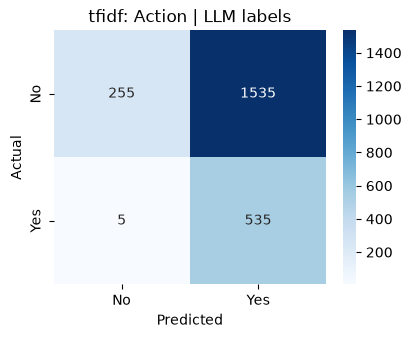

Student: tfidf / Comedy | macro-F1=0.655 | weights={0: 1, 1: 8}
              precision    recall  f1-score   support

           0       0.80      0.81      0.80      1650
           1       0.52      0.49      0.51       680

    accuracy                           0.72      2330
   macro avg       0.66      0.65      0.65      2330
weighted avg       0.71      0.72      0.72      2330



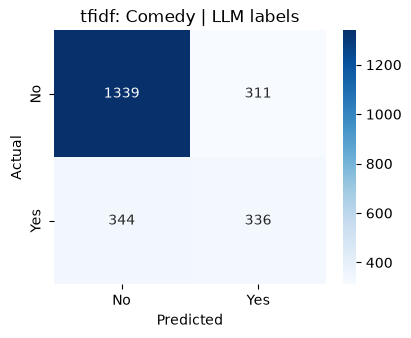

Student: tfidf / Horror | macro-F1=0.756 | weights={0: 1, 1: 2}
              precision    recall  f1-score   support

           0       0.96      0.81      0.88      1890
           1       0.51      0.84      0.63       440

    accuracy                           0.82      2330
   macro avg       0.73      0.83      0.76      2330
weighted avg       0.87      0.82      0.83      2330



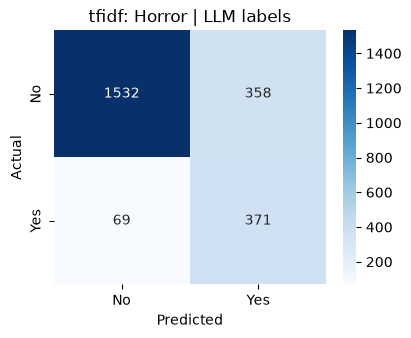

Student: emb-minilm / Action | macro-F1=0.563 | weights={0: 1, 1: 8}
              precision    recall  f1-score   support

           0       0.90      0.51      0.65      1790
           1       0.33      0.81      0.47       540

    accuracy                           0.58      2330
   macro avg       0.62      0.66      0.56      2330
weighted avg       0.77      0.58      0.61      2330



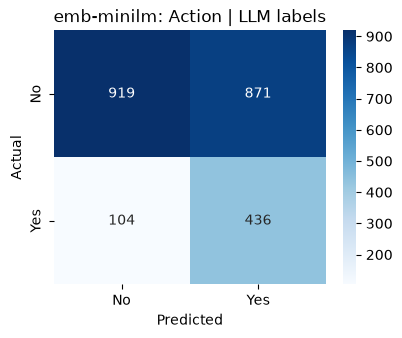

Student: emb-minilm / Comedy | macro-F1=0.596 | weights=balanced
              precision    recall  f1-score   support

           0       0.80      0.62      0.70      1650
           1       0.41      0.62      0.49       680

    accuracy                           0.62      2330
   macro avg       0.60      0.62      0.60      2330
weighted avg       0.69      0.62      0.64      2330



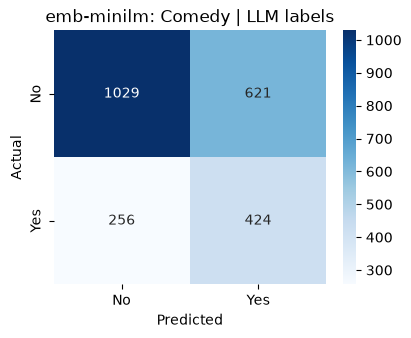

Student: emb-minilm / Horror | macro-F1=0.605 | weights=None
              precision    recall  f1-score   support

           0       0.92      0.64      0.75      1890
           1       0.33      0.75      0.46       440

    accuracy                           0.66      2330
   macro avg       0.62      0.70      0.61      2330
weighted avg       0.81      0.66      0.70      2330



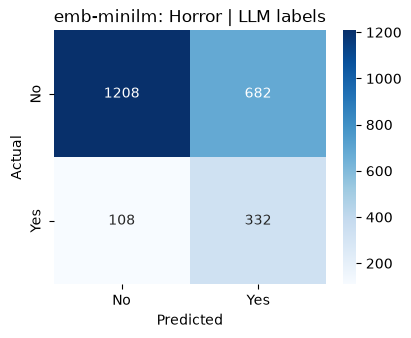

In [17]:
# Align teacher-labeled rows back to their original train-matrix positions.
positions = pd.Series(np.arange(len(train_df)), index=train_df.imdb_id)
sample_positions = positions.loc[pseudo.imdb_id].to_numpy()
pseudo_results = []
for rep, (X_train, X_test) in representations.items():
    X_sample = X_train[sample_positions]
    for genre in GENRES:
        y_pseudo = pseudo[f"pred_{genre.lower()}"].astype(int).to_numpy()
        if len(np.unique(y_pseudo)) != 2 or np.bincount(y_pseudo).min() < 5:
            raise ValueError(f"Not enough examples in both pseudo-label classes: {genre}")
        search = tune_logreg(X_sample, y_pseudo)
        pred = search.predict(X_test)
        y_true = test_df[genre].to_numpy()
        macro_f1 = f1_score(y_true, pred, average="macro")
        pseudo_results.append({"label_source": "LLM", "representation": rep,
                               "genre": genre, "macro_f1": macro_f1})
        print(f"Student: {rep} / {genre} | macro-F1={macro_f1:.3f} | weights={search.best_params_['class_weight']}")
        print(classification_report(y_true, pred, zero_division=0))
        cm = confusion_matrix(y_true, pred, labels=[0, 1])
        plt.figure(figsize=(4.4, 3.3))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
        plt.xlabel("Predicted");plt.ylabel("Actual");plt.title(f"{rep}: {genre} | LLM labels")
        plt.show()

### 8. Leaderboard: what changed when I replaced the labels?

I compare the IMDB-trained and LLM-trained logistic regression models using **macro-F1 on the same untouched test set**. I also show the teacher's own F1 on the sampled training plots, but I keep that as a reference—not a test result. The real question is whether the cheaper student models can hold up when I replace the training labels with LLM predictions.

In [18]:
model_scores = pd.DataFrame(test_results + pseudo_results)
leaderboard = (model_scores.pivot_table(index=["label_source", "representation"],
                                       columns="genre", values="macro_f1")
               .reset_index())
leaderboard["mean_macro_f1"] = leaderboard[GENRES].mean(axis=1)
leaderboard = leaderboard.sort_values("mean_macro_f1", ascending=False).reset_index(drop=True)
leaderboard.insert(0, "rank", np.arange(1, len(leaderboard) + 1))
teacher_reference = {"rank": "—", "label_source": "Teacher — annotation sample ONLY (NOT test)",
                     "representation": "LLM direct"}
teacher_reference.update({genre: teacher_scores[genre]["f1"] for genre in GENRES})
teacher_reference["mean_macro_f1"] = np.nan  # not the same metric or evaluation set
full_leaderboard = pd.concat([leaderboard, pd.DataFrame([teacher_reference])], ignore_index=True)
display(full_leaderboard.round(3))

comparison = (model_scores.pivot_table(index=["representation", "genre"], columns="label_source", values="macro_f1"))
comparison["LLM_minus_IMDB"] = comparison["LLM"] - comparison["IMDB"]
display(comparison.round(3))
print("Average change in held-out macro-F1 (LLM minus IMDB):", round(comparison["LLM_minus_IMDB"].mean(), 3))

,rank,label_source,representation,Action,Comedy,Horror,mean_macro_f1
0,1,IMDB,tfidf,0.778,0.733,0.830,0.780
1,2,IMDB,emb-minilm,0.770,0.693,0.757,0.740
2,3,LLM,emb-minilm,0.563,0.596,0.605,0.588
3,4,LLM,tfidf,0.329,0.655,0.756,0.580
4,—,Teacher — annotation sample ONLY (NOT test),LLM direct,0.752,0.821,0.865,NaN


label_source            IMDB    LLM  LLM_minus_IMDB
representation genre                               
emb-minilm     Action  0.770  0.563          -0.207
               Comedy  0.693  0.596          -0.096
               Horror  0.757  0.605          -0.151
tfidf          Action  0.778  0.329          -0.448
               Comedy  0.733  0.655          -0.078
               Horror  0.830  0.756          -0.074

Average change in held-out macro-F1 (LLM minus IMDB): -0.176


**How I interpret the results:** The `LLM_minus_IMDB` values tell me how much held-out macro-F1 changed when I used teacher-generated labels. A negative number means performance dropped; a positive number means the student did better for that representation and genre. I would not automatically give the LLM credit for every increase, though: the pseudo-label models use a much smaller, deliberately genre-enriched training sample. That means label source and training-set size are changing together, so I treat this as a practical comparison rather than a clean causal experiment. The actual score difference is calculated above, not assumed in advance.

### 9. Export and submission check

I save the six IMDB-trained models and the fitted TF-IDF vectorizer/scaler under `models/` because Notebook 3 needs them. I keep the embedding caches, teacher checkpoint, pseudo-label CSV, and comparison CSVs outside the GitHub repo. Before I submit anything, I need to run the full notebook with the completed teacher sample, verify the leaderboard is populated, and export `environment.yml` from **my actual `moviegenre` environment**.

In [19]:
cv_table.to_csv(ARTIFACT_DIR / "cross_validation_results.csv", index=False)
full_leaderboard.to_csv(ARTIFACT_DIR / "leaderboard.csv", index=False)
expected_model_files = [MODEL_DIR / f"P3_N2_{rep}_logreg_{genre.lower()}.pkl"
                        for rep in representations for genre in GENRES]
expected_model_files += [MODEL_DIR / "P3_N2_tfidf_vectorizer.pkl",
                         MODEL_DIR / "P3_N2_tfidf_scaler.pkl"]
missing = [str(path) for path in expected_model_files if not path.exists()]
assert not missing, f"Missing model artifacts: {missing}"
print("All required exported models and TF-IDF preprocessors exist.")
print("Keep OUT of GitHub:", ARTIFACT_DIR)
print("Now run: conda env export --no-builds > environment.yml")

All required exported models and TF-IDF preprocessors exist.
Keep OUT of GitHub: /Users/timhamilton/Downloads/local_artifacts
Now run: conda env export --no-builds > environment.yml
